In [84]:
%load_ext byname

The byname extension is already loaded. To reload it, use:
  %reload_ext byname


In [85]:
from notebook_cache import NotebookCache

# results and prints live on disk, so they survive kernel restarts; one folder per notebook
cache = NotebookCache("../cache/act_byname")

# ACT, built forward (byname + cache)

Redo of `act.ipynb`: same data, split and eval seeds. Expensive steps are `@cache`d, so a kernel restart costs nothing.

### step 0 — the data, as in BC


In [86]:
from pathlib import Path

import numpy as np
from lerobot.datasets.lerobot_dataset import LeRobotDataset
from numpy.typing import NDArray

np.set_printoptions(precision=3, suppress=True)
REPO = Path.cwd().parent

In [87]:
@cache
def load_table():
    # straight from the table, no video decode
    ds = LeRobotDataset("dream_robot/pick_place_cube", root=REPO / "data/robosuite/pick_place_cube")
    return (
        state=np.asarray(ds.hf_dataset["observation.state"], dtype=np.float32),  # [N, 8]
        action=np.asarray(ds.hf_dataset["action"], dtype=np.float32),  # [N, 8]
        episode=np.asarray(
            ds.hf_dataset["episode_index"], dtype=np.int64
        ),  # [N], which demo each frame is from
    )

In [88]:
(state=, action=, episode=) = load_table()
val_eps = np.random.default_rng(0).permutation(25)[:5]  # same 5 held-out demos as bc_2 and act
is_val = np.isin(episode, val_eps)  # [N]
print(f"{state.shape=}  {action.shape=}  {val_eps=}  train {(~is_val).sum()}  val {is_val.sum()}")

state.shape=(5288, 8)  action.shape=(5288, 8)  val_eps=array([19,  4, 10, 11, 24])  train 4218  val 1070


### step 1 — the target is a chunk: the next K actions, not one


In [89]:
def make_chunks(action: NDArray[np.float32], episode: NDArray[np.int64], K: int):
    # demo e's last row is where its run of rows ends, since demos are stored in order
    assert (np.diff(episode) >= 0).all(), "demos not stored in order"
    last = np.searchsorted(episode, episode, side="right") - 1  # [N]
    idx = np.arange(len(action))[:, None] + np.arange(K)  # [N, K], rows t .. t+K-1
    pad = idx > last[:, None]  # [N, K], True where the chunk runs past its demo's end
    chunks = action[
        np.minimum(idx, last[:, None])
    ]  # [N, K, 8], past the end: repeat the final action
    return (chunks=, pad=)


K = 50  # chunk length: 50 steps = 1.7 s at 30 Hz; a demo is ~210 steps
(chunks=, pad=) = make_chunks(action, episode, K)
print(f"{chunks.shape=}  {pad.shape=}")
print(f"frames whose chunk is partly padding: {pad.any(1).sum()} of {len(action)}")


chunks.shape=(5288, 50, 8)  pad.shape=(5288, 50)
frames whose chunk is partly padding: 1225 of 5288


### step 2 — what a chunk looks like


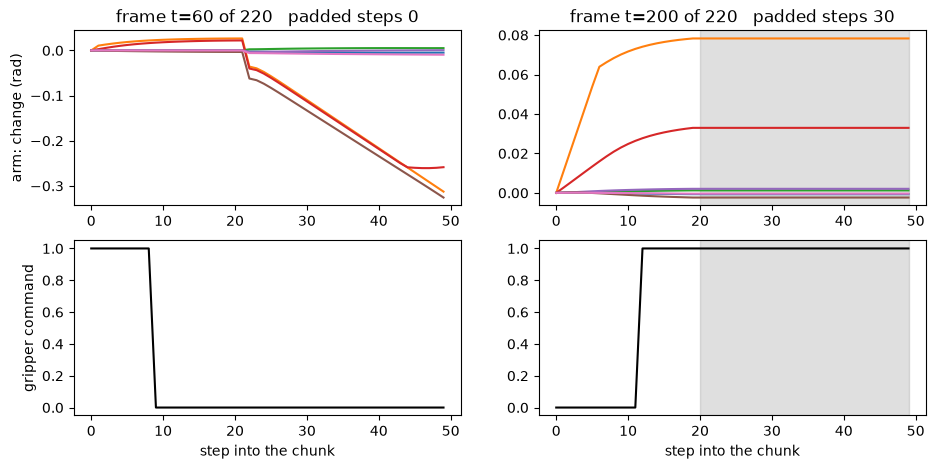

In [90]:
import matplotlib.pyplot as plt

rows = np.flatnonzero(episode == 2)  # demo 2's frames, as in bc_2
fig = plt.figure(figsize=(11, 5))
arm = [fig.add_subplot(2, 2, 1 + col) for col in range(2)]  # top row: 7 arm joints
grip = [fig.add_subplot(2, 2, 3 + col, sharex=arm[col]) for col in range(2)]  # bottom row: gripper
for col, t in enumerate([60, len(rows) - 20]):  # mid-demo, and 20 steps before the end
    ch = chunks[rows[t]]  # [K, 8], the plan from frame t
    arm[col].plot(ch[:, :7] - ch[0, :7])  # as change from the chunk's first action
    grip[col].plot(ch[:, 7], color="k")  # gripper command: 1 open, 0 close
    n_pad = int(pad[rows[t]].sum())
    if n_pad:
        for a in (arm[col], grip[col]):
            a.axvspan(
                K - n_pad, K - 1, color="grey", alpha=0.25
            )  # padded: repeats the final action
    arm[col].set_title(f"frame t={t} of {len(rows)}   padded steps {n_pad}")
    grip[col].set_xlabel("step into the chunk")
arm[0].set_ylabel("arm: change (rad)")
grip[0].set_ylabel("gripper command")
plt.show()


### step 3 — both cameras into RAM (~20 s the first time, cached after)


In [91]:
import torch
from torch import Tensor

In [92]:
@cache
def load_images():
    # every frame decoded from both videos once, kept as uint8 (~0.5 GB), as bc_2 steps 8 and 21
    ds = LeRobotDataset("dream_robot/pick_place_cube", root=REPO / "data/robosuite/pick_place_cube")
    top = np.zeros((len(ds), 3, 128, 128), dtype=np.uint8)  # [N, 3, H, W]
    wrist = np.zeros_like(top)
    for i in range(len(ds)):
        item: dict[str, Tensor] = ds[i]  # this frame, decoded from both videos
        top[i] = (item["observation.images.top"] * 255).round().to(torch.uint8).numpy()
        wrist[i] = (item["observation.images.wrist"] * 255).round().to(torch.uint8).numpy()
    return (top=, wrist=)

In [93]:
(top=, wrist=) = load_images()
print(f"{top.shape=}  {wrist.shape=}")

top.shape=(5288, 3, 128, 128)  wrist.shape=(5288, 3, 128, 128)


### step 4 — to the GPU, plus normalisation stats


In [94]:
dev = "cuda"


def to_gpu(x: NDArray):
    # split once by episode; images stay uint8 until a batch is drawn
    return (train=torch.tensor(x[~is_val]).to(dev), val=torch.tensor(x[is_val]).to(dev))


def mean_std(x: Tensor, dims: tuple[int, ...]):
    # keepdim leaves a 1 for each reduced dim, so the stats broadcast straight back over x
    return (mean=x.mean(dims, keepdim=True), std=x.std(dims, keepdim=True))


data = (
    top=to_gpu(top),
    wrist=to_gpu(wrist),
    state=to_gpu(state),
    chunks=to_gpu(chunks),
    pad=to_gpu(pad),
)

# from train only, as bc_2 steps 19 and 22. Action stats from single actions: a chunk is made of
# the same actions, so they apply to every step of it
stats = (
    state=mean_std(data.state.train, (0,)),  # [1, 8] each
    action=mean_std(
        data.chunks.train[:, 0], (0,)
    ),  # [1, 8] each; chunk step 0 = that frame's action
    top=mean_std(
        data.top.train[::20].float() / 255, (0, 2, 3)
    ),  # [1, 3, 1, 1] each, every 20th frame
    wrist=mean_std(data.wrist.train[::20].float() / 255, (0, 2, 3)),
)
print(f"{data.chunks.train.shape=}  {data.chunks.val.shape=}  {data.pad.train.shape=}")
print("action std", stats.action.std.cpu().numpy())


data.chunks.train.shape=torch.Size([4218, 50, 8])  data.chunks.val.shape=torch.Size([1070, 50, 8])  data.pad.train.shape=torch.Size([4218, 50])
action std [[0.158 0.191 0.035 0.135 0.06  0.161 0.196 0.48 ]]


### step 5 — BC's image encoder, as in bc_2


In [95]:
from torch import nn


# bc_2's image encoder, unchanged: conv stack (step 9) without its last ReLU, then spatial softmax (step 15)
def make_conv() -> nn.Sequential:
    return nn.Sequential(
        nn.Conv2d(3, 32, 5, 2, 2),  # -> [B, 32, 64, 64]
        nn.ReLU(),
        nn.Conv2d(32, 64, 3, 2, 1),  # -> [B, 64, 32, 32]
        nn.ReLU(),
        nn.Conv2d(64, 128, 3, 2, 1),  # -> [B, 128, 16, 16]
        nn.ReLU(),
        nn.Conv2d(128, 64, 3, 1, 1),  # -> [B, 64, 16, 16], no ReLU: the softmax wants negatives
    )


class SpatialSoftmax(nn.Module):
    cell_x: Tensor  # buffers, declared so the checker doesn't read them as Tensor | Module
    cell_y: Tensor

    def __init__(self, h: int, w: int):
        super().__init__()
        self.log_t = nn.Parameter(torch.zeros(()))  # learned temperature, T = exp(log_t) > 0
        self.register_buffer("cell_x", torch.linspace(-1, 1, w).repeat(h))  # [H*W]
        self.register_buffer("cell_y", torch.linspace(-1, 1, h).repeat_interleave(w))  # [H*W]

    def forward(self, f: Tensor) -> Tensor:
        # f: [B, C, H, W] feature maps
        # out: [B, 2C], an (x, y) per map
        B, C, H, W = f.shape
        p = torch.softmax(f.reshape(B, C, H * W) / self.log_t.exp(), dim=-1)  # [B, C, H*W]
        return torch.stack([p @ self.cell_x, p @ self.cell_y], dim=-1).reshape(B, 2 * C)


enc = nn.Sequential(make_conv(), SpatialSoftmax(16, 16)).to(dev)
x = data.top.train[:4].float() / 255  # [4, 3, 128, 128]
points: Tensor = enc((x - stats.top.mean) / stats.top.std)  # [4, 128]: 64 maps -> 64 (x, y) points
print(f"{x.shape} -> {points.shape}")


torch.Size([4, 3, 128, 128]) -> torch.Size([4, 128])


### step 6 — `ChunkNet`: BC's net, but the head outputs a chunk


In [96]:
class ChunkNet(nn.Module):
    # bc_2's TwoCamNet (step 23) with one change: the head outputs K actions, not 1
    def __init__(self):
        super().__init__()
        self.top = nn.Sequential(make_conv(), SpatialSoftmax(16, 16))
        self.wrist = nn.Sequential(make_conv(), SpatialSoftmax(16, 16))
        self.head = nn.Sequential(nn.Linear(128 * 2 + 8, 512), nn.ReLU(), nn.Linear(512, K * 8))

    def forward(self, top: Tensor, wrist: Tensor, state: Tensor) -> Tensor:
        # top, wrist: [B, 3, 128, 128] floats in [0, 1]
        # state: [B, 8] radians
        # out: [B, K, 8] radians, the next K actions
        f_top: Tensor = self.top((top - stats.top.mean) / stats.top.std)  # [B, 128]
        f_wrist: Tensor = self.wrist((wrist - stats.wrist.mean) / stats.wrist.std)  # [B, 128]
        st = (state - stats.state.mean) / stats.state.std
        out: Tensor = self.head(torch.cat([f_top, f_wrist, st], dim=-1))  # [B, 264] -> [B, K*8]
        out = out.reshape(-1, K, 8)  # [B, K, 8] in std units
        # [1, 8] stats broadcast over every chunk step
        return out * stats.action.std + stats.action.mean


net = ChunkNet().to(dev)
print("params", sum(p.numel() for p in net.parameters()))
i = torch.arange(4, device=dev)
pred: Tensor = net(
    data.top.train[i].float() / 255,
    data.wrist.train[i].float() / 255,
    data.state.train[i],
)
print(pred.shape)  # [4, K, 8]


params 678034
torch.Size([4, 50, 8])


### step 7 — the loss: L1 over the chunk, padded steps skipped


In [97]:
from typing import Literal


def get_batch(split: Literal["train", "val"], i: Tensor):
    # rows i of one split, every field at once; images to floats in [0, 1] only now
    def take(x: (train: Tensor, val: Tensor)) -> Tensor:
        return (x.train if split == "train" else x.val)[i]

    return (
        top=take(data.top).float() / 255,  # [B, 3, 128, 128]
        wrist=take(data.wrist).float() / 255,  # [B, 3, 128, 128]
        state=take(data.state),  # [B, 8]
        chunks=take(data.chunks),  # [B, K, 8]
        pad=take(data.pad),  # [B, K] bool
    )


def chunk_l1(pred: Tensor, target: Tensor, pad: Tensor) -> Tensor:
    # pred, target: [B, K, 8] radians
    # pad: [B, K] bool, True where the step is padding past the demo's end
    # out: [], mean |error| in std units (bc_2 step 20) over real steps only
    err = ((pred - target) / stats.action.std).abs()  # [B, K, 8]
    keep = (~pad)[..., None].float()  # [B, K, 1], 0 on padded steps
    return (err * keep).sum() / (keep.sum() * 8)  # divide by the number of real values, not B*K*8


torch.manual_seed(0)
b = get_batch(
    "train", torch.randint(0, len(data.state.train), (64,), device=dev)
)  # 64 random frames
with torch.no_grad():
    pred: Tensor = net(b.top, b.wrist, b.state)  # [64, K, 8]
print(f"padded steps in this batch: {b.pad.float().mean():.0%}")
print(f"untrained loss {chunk_l1(pred, b.chunks, b.pad):.3f}")


padded steps in this batch: 7%
untrained loss 0.795


### step 8 — train `ChunkNet` (~45 s the first time, cached after)


In [98]:
import torch.nn.functional as F


def random_shift(x: Tensor, pad: int = 4) -> Tensor:
    # as bc_2 step 30
    # x: [B, 3, H, W]
    # out: [B, 3, H, W], the whole batch moved by up to pad px each way, edge pixels repeated
    B, C, H, W = x.shape
    x = F.pad(x, (pad, pad, pad, pad), mode="replicate")  # [B, 3, H + 2p, W + 2p]
    dy, dx = (int(d) for d in torch.randint(0, 2 * pad + 1, (2,)))
    return x[:, :, dy : dy + H, dx : dx + W]


@torch.no_grad()
def val_error(net: nn.Module) -> Tensor:
    # out: [8], mean |error| of each chunk's FIRST action on val, radians, comparable with bc_2.
    # 256 frames at a time, never shifted
    n = len(data.state.val)
    firsts: list[Tensor] = []
    for j in range(0, n, 256):
        b = get_batch("val", torch.arange(j, min(j + 256, n), device=dev))
        pred: Tensor = net(b.top, b.wrist, b.state)  # [<=256, K, 8]
        firsts.append(pred[:, 0])
    return (torch.cat(firsts) - data.chunks.val[:, 0]).abs().mean(0)

In [99]:
@cache(2)
def train(seed: int = 0, steps: int = 3000, shift: int = 4, lr: float = 1e-3):
    # bc_2's train() with the chunk loss; both cameras, normalised, shifted
    torch.manual_seed(seed)
    net = ChunkNet().to(dev)
    opt = torch.optim.AdamW(net.parameters(), lr=lr)
    err = torch.zeros(8)
    for step in range(steps + 1):
        b = get_batch("train", torch.randint(0, len(data.state.train), (64,), device=dev))
        pred: Tensor = net(random_shift(b.top, shift), random_shift(b.wrist, shift), b.state)
        loss = chunk_l1(pred, b.chunks, b.pad)
        opt.zero_grad()
        loss.backward()
        opt.step()
        if step % 500 == 0:
            err = val_error(net).cpu()
            print(
                f"{step:5d}  train {loss.item():.4f}  val arm {err[:7].mean():.4f}  gripper {err[7]:.4f}"
            )
    # weights on the CPU, so the cache holds no GPU tensors
    trained: dict[str, Tensor] = net.state_dict()
    return (weights={k: v.cpu() for k, v in trained.items()}, err=err)

In [100]:
(weights=, err=) = train(seed=0)
net = ChunkNet().to(dev)
net.load_state_dict(weights)

    0  train 0.7986  val arm 0.1144  gripper 0.4600
  500  train 0.1119  val arm 0.0097  gripper 0.0777
 1000  train 0.0840  val arm 0.0079  gripper 0.0608
 1500  train 0.0684  val arm 0.0072  gripper 0.0545
 2000  train 0.0615  val arm 0.0062  gripper 0.0502
 2500  train 0.0620  val arm 0.0071  gripper 0.0575
 3000  train 0.0566  val arm 0.0060  gripper 0.0448


<All keys matched successfully>